# Experimentación — de la estrategia semanal directa al modelo ganador

Se intentó primero una estrategia **directa** sobre
agregados semanales; los resultados no fueron prometedores; se probó la
**recursiva walk-forward** semanal junto con una configuracion ensable,
diario justifica el **modelo ganador del proyecto demo**:

> **LGBM diario one-step recursivo + ensamble ponderado con lag-1**

In [1]:
from pathlib import Path

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from sklearn.dummy import DummyRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import ElasticNetCV, RidgeCV, Ridge, ElasticNet
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler


import lightgbm as lgb
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "data" / "raw" / "historico_equipos.csv").is_file():
            return cand
    raise FileNotFoundError("No se encontro data/raw/historico_equipos.csv")

ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"
FIG_EXP = ROOT / "reports" / "figures" / "experimentos"
FIG_EXP.mkdir(parents=True, exist_ok=True)

def savefig(name, dirpath=FIG_EXP):
    path = dirpath / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")

def get_metrics(y_true, y_pred):
    return pd.Series({
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100
    })

TARGETS = ["Price_Equipo1", "Price_Equipo2"]
INPUTS = ["Price_X", "Price_Y", "Price_Z"]

## 1. Setup semanal (W-MON), malla y diagnóstico

Agregación semanal con cierre en lunes (promedio), malla completa `asfreq`
y política explícita de huecos (`ffill(limit=2)`). Horizonte de referencia :
**H = 4 semanas**; lags propuestos hasta 26.

In [2]:
df_raw = pd.read_csv(RAW / "historico_equipos.csv", parse_dates=["Date"]).set_index("Date")
HORIZON = 26
MAX_LAG = 26

weekly = df_raw.resample("W-MON").mean().asfreq("W-MON")
missing = weekly[weekly.isna().any(axis=1)]
print(f"Semanas totales: {len(weekly)} | con NaN: {len(missing)}")
display(missing.head(10))
weekly = weekly.ffill(limit=2)
print("Tras ffill(limit=2) — NaN restantes:", int(weekly.isna().any(axis=1).sum()))
display(weekly[TARGETS].describe().T)

Semanas totales: 714 | con NaN: 0


,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,


Tras ffill(limit=2) — NaN restantes: 0


,count,mean,std,min,25%,50%,75%,max
Price_Equipo1,714.000,459.902,113.212,211.708,398.824,449.802,516.115,828.892
Price_Equipo2,714.000,889.858,169.078,581.916,779.071,871.400,979.261,"1,559.590"


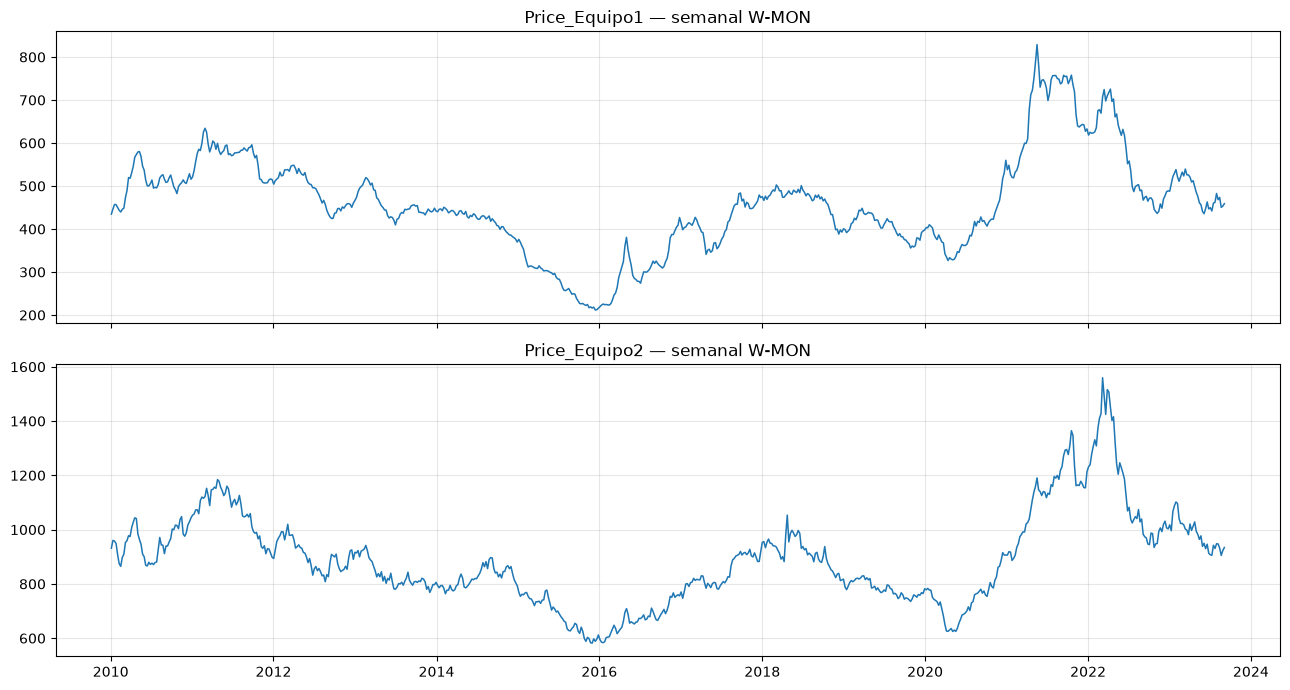

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, col in zip(axes, TARGETS):
    ax.plot(weekly.index, weekly[col], lw=1.1)
    ax.set_title(f"{col} — semanal W-MON")
    ax.grid(alpha=0.3)
plt.tight_layout()
savefig("01_series_semanales")
plt.show()

## 2. Baselines semanales (naive RW y media histórica)

Split fijo: últimas 26 semanas como test. Métricas en **precio real**.
Sirven de referencia: cualquier modelo debe superar al naive (P_t = P_{t-H}).

In [4]:
TEST_WEEKS = 52

base_rows = []
preds_base = {}
for target in TARGETS:
    s = weekly[target].dropna()
    train, test = s.iloc[:-TEST_WEEKS], s.iloc[-TEST_WEEKS:]
    naive = train.iloc[-1]  # random walk: último precio conocido = forecast plano
    media = train.mean()
    for name, pred in [("Naive (ultimo precio)", naive), ("Media historica", media)]:
        yhat = pd.Series(pred, index=test.index)
        base_rows.append({"target": target, "modelo": name,
                          **get_metrics(test, yhat).to_dict()})
        preds_base[(target, name)] = yhat

display(pd.DataFrame(base_rows).set_index(["target", "modelo"]))

MAE    RMSE  MAPE (%)
target        modelo                                        
Price_Equipo1 Naive (ultimo precio) 26.135  33.414     5.265
              Media historica       28.603  37.704     5.695
Price_Equipo2 Naive (ultimo precio) 38.942  47.697     3.956
              Media historica       99.517 110.356     9.925

## 3. Estrategia directa

**Horizonte: H = 26 semanas (6 meses)** — alineado con la ventana de planeación hipotetica del caso
(`HORIZON = 26` en el setup; se usa en toda la sección semanal: directa).

Para continuar/descartar se hicieron pruebas para identificar si un lag mayor a 1 aportaba señal a la predccion


==================== Price_Equipo1 ====================


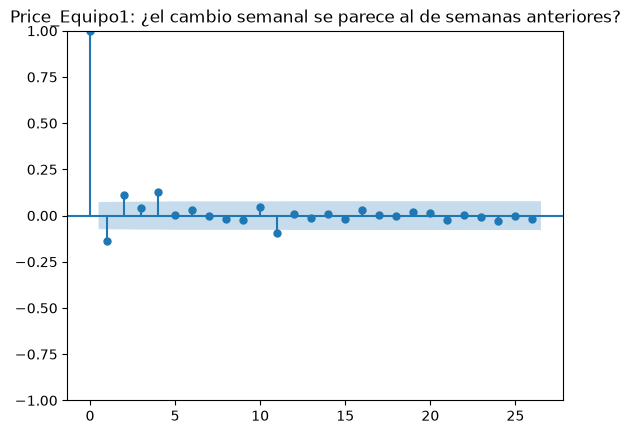

,error naive,error modelo,modelo / naive,¿gana con margen (>10%)?
bloque,,,,
1,135.700,141.300,1.041,False
2,46.000,54.600,1.187,False



==================== Price_Equipo2 ====================


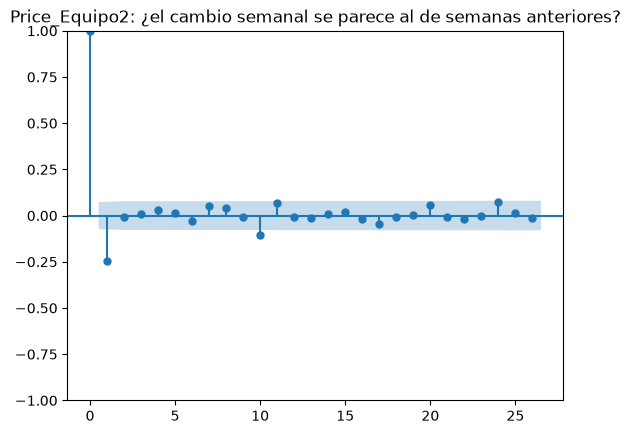

,error naive,error modelo,modelo / naive,¿gana con margen (>10%)?
bloque,,,,
1,221.100,249.900,1.130,False
2,77.200,98.100,1.270,False


In [5]:
from statsmodels.graphics.tsaplots import plot_acf

for t in TARGETS:
    print(f"\n==================== {t} ====================")

    # ---- PASO 1: gráfica de autocorrelación ----
    # Uso el último dato de cada semana (no el promedio) para no mezclar días
    r = np.log(df_raw[t].resample("W-MON").last().dropna()).diff().dropna()
    plot_acf(r, lags=26, title=f"{t}: ¿el cambio semanal se parece al de semanas anteriores?")
    plt.show()

    p = weekly[t]
    X = pd.DataFrame({"cambio_4s": p.pct_change(4), 
                      "cambio_13s": p.pct_change(13),    
                      "cambio_26s": p.pct_change(26)}) 
    y = p.pct_change(HORIZON).shift(-HORIZON)            
    datos = pd.concat([X, y.rename("y")], axis=1).dropna()

    ultimas_52 = datos.index[-52:]
    bloques = [ultimas_52[:26], ultimas_52[26:]]

    filas = []
    for i, bloque in enumerate(bloques, start=1):

        corte = bloque[0] - pd.Timedelta(weeks=HORIZON)
        train = datos.loc[:corte]
        modelo = make_pipeline(StandardScaler(), Ridge(alpha=100))
        modelo.fit(train.drop(columns="y"), train["y"])

        precio_hoy = p.loc[bloque]                                  
        precio_real = p.shift(-HORIZON).loc[bloque]                  
        pred = precio_hoy * (1 + modelo.predict(datos.loc[bloque].drop(columns="y")))

        err_naive = (precio_real - precio_hoy).abs().mean()
        err_modelo = (precio_real - pred).abs().mean()
        filas.append({"bloque": i,
                      "error naive": round(err_naive, 1),
                      "error modelo": round(err_modelo, 1),
                      "modelo / naive": round(err_modelo / err_naive, 3),
                      "¿gana con margen (>10%)?": err_modelo / err_naive < 0.90})
    display(pd.DataFrame(filas).set_index("bloque"))

In [12]:
N_BLOQUES = 8            
BLOQUE = HORIZON
USAR_INPUTS = True      

def modelos():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=100)),
        "LightGBM": lgb.LGBMRegressor(n_estimators=150, learning_rate=0.03, max_depth=3,
                                      min_child_samples=20, random_state=21, verbose=-1),
    }

def preparar(target, con_pista=False):
    p = weekly[target]
    X = pd.DataFrame({"cambio_4s": p.pct_change(4),
                      "cambio_13s": p.pct_change(13),
                      "cambio_26s": p.pct_change(26)})
    if USAR_INPUTS:
        for c in INPUTS:
            X[f"{c}_4s"] = weekly[c].pct_change(4)
    y = p.pct_change(HORIZON).shift(-HORIZON)          
    if con_pista:                                      
        rng = np.random.default_rng(0)
        X["pista"] = y + rng.normal(0, y.std(), len(y))
    datos = pd.concat([X, y.rename("y")], axis=1).dropna()
    return p, datos

def backtest(target, con_pista=False):
    p, datos = preparar(target, con_pista)
    n = len(datos)
    filas, preds = [], {m: [] for m in modelos()}
    for b in range(N_BLOQUES):
        ini = n - (N_BLOQUES - b) * BLOQUE
        bloque = datos.index[ini: ini + BLOQUE]
        corte = bloque[0] - pd.Timedelta(weeks=HORIZON)     
        train = datos.loc[:corte]
        precio_hoy = p.loc[bloque]
        precio_real = p.shift(-HORIZON).loc[bloque]
        err_naive = (precio_real - precio_hoy).abs().mean()
        for nombre, m in modelos().items():
            m.fit(train.drop(columns="y"), train["y"])
            r_hat = m.predict(datos.loc[bloque].drop(columns="y"))
            err = (precio_real - precio_hoy * (1 + r_hat)).abs().mean()
            filas.append({"bloque": b + 1, "modelo": nombre, "modelo/naive": err / err_naive})
            preds[nombre].append(pd.Series(r_hat, index=bloque))
    preds = {k: pd.concat(v) for k, v in preds.items()}
    real = datos.loc[preds["Ridge"].index, "y"]
    return pd.DataFrame(filas), preds, real

def prueba_desfase(pred, real):
    """¿La correlación real es mayor que la que sale al mover el futuro a otras fechas?"""
    pred, real = np.asarray(pred), np.asarray(real)
    corr_real = np.corrcoef(pred, real)[0, 1]
    sims = [np.corrcoef(pred, np.roll(real, k))[0, 1] for k in range(HORIZON, len(real) - HORIZON + 1)]
    p_valor = (1 + np.sum(np.array(sims) >= corr_real)) / (1 + len(sims))
    return corr_real, p_valor

for t in TARGETS:
    print(f"\n==================== {t} ====================")
    res, pred, real = backtest(t)
    resumen = []
    for nombre in modelos():
        r = res[res.modelo == nombre]["modelo/naive"]
        c, pv = prueba_desfase(pred[nombre], real)
        resumen.append({"modelo": nombre,
                        "bloques ganados": f"{int((r < 1).sum())} de {N_BLOQUES}",
                        "modelo/naive promedio": round(r.mean(), 3),
                        "corr con el futuro": round(c, 3),
                        "p (prueba del azar)": round(pv, 3)})
    print("Pruebas 1 y 2 (datos reales):")
    display(pd.DataFrame(resumen).set_index("modelo"))

    res_c, _, _ = backtest(t, con_pista=True)
    ctrl = res_c.groupby("modelo")["modelo/naive"].mean().round(3)
    print("Prueba 3 (control: con pista del futuro) — modelo/naive promedio:")
    display(ctrl.to_frame("modelo/naive con pista"))


==================== Price_Equipo1 ====================
Pruebas 1 y 2 (datos reales):


,bloques ganados,modelo/naive promedio,corr con el futuro,p (prueba del azar)
modelo,,,,
Ridge,3 de 8,1.123,0.010,0.323
LightGBM,3 de 8,1.191,0.007,0.589


Prueba 3 (control: con pista del futuro) — modelo/naive promedio:


,modelo/naive con pista
modelo,
LightGBM,0.838
Ridge,0.777



==================== Price_Equipo2 ====================
Pruebas 1 y 2 (datos reales):


,bloques ganados,modelo/naive promedio,corr con el futuro,p (prueba del azar)
modelo,,,,
Ridge,4 de 8,1.036,-0.096,0.392
LightGBM,3 de 8,1.102,-0.161,0.665


Prueba 3 (control: con pista del futuro) — modelo/naive promedio:


,modelo/naive con pista
modelo,
LightGBM,0.823
Ridge,0.774


**Veredicto semanal:** las mejoras son marginales e insuficientes. Ningun modelo
supero el naive, no hay evidencia clara de que exista una señal mas alla de lag1
(consistente con el EDA: autocorrelación de retornos ~0 más allá de L1) por lo 
que se cambia de frecuencia.

## 6. Puente diario: mismo problema a frecuencia diaria

El EDA mostró señal en retornos diarios (lag 0-1). Reintentamos one-step
**diario** con lags propios, considerando que la empresa no cuenta con forma
de preveer los precios de X,Y Z, walk-forward recursivo 130 días
(≈6 meses) y comparación directa contra naive. Este es el experimento que
selló la estrategia del proyecto demo.

In [7]:
daily = df_raw[TARGETS + INPUTS].sort_index()
H_DAYS = 130
TEST_DAYS = 130
LAGS_D = [1, 2, 3, 5, 10, 20, 60]

def build_daily_features(df, target, lags=LAGS_D):
    out = pd.DataFrame(index=df.index)
    for l in lags:
        out[f"{target}_lag{l}"] = df[target].shift(l)
        for col in INPUTS:
            out[f"{col}_lag{l}"] = df[col].shift(l)
    for w in (5, 20, 60):
        out[f"{target}_roll{w}_mean"] = df[target].shift(1).rolling(w).mean()
        out[f"{target}_roll{w}_std"] = df[target].shift(1).rolling(w).std()
    out["dow"] = df.index.dayofweek
    out["month"] = df.index.month
    return out


def recursive_daily_forecast(df, target, model, lags=LAGS_D, horizon=TEST_DAYS):
    """Forecast recursivo: predice t+1, lo appendea al historial y sigue."""
    hist = df.copy()
    preds = []
    for i in range(horizon):
        feats = build_daily_features(hist, target, lags).iloc[[-1]]
        yhat = model.predict(feats)[0]
        preds.append(yhat)
        last_date = hist.index[-1] + pd.Timedelta(days=1)
        while last_date.weekday() >= 5:
            last_date += pd.Timedelta(days=1)
        row = {target: yhat}
        for col in INPUTS:
            row[col] = hist[col].iloc[-1]  # exog estatica en el corto plazo
        hist = pd.concat([hist, pd.DataFrame([row], index=[last_date])])
    idx = hist.index[-horizon:]
    return pd.Series(preds, index=idx)

In [8]:
daily_results = {}
for target in TARGETS:
    df_feat = build_daily_features(daily, target).dropna()
    df_feat[target] = daily[target].reindex(df_feat.index)
    split = len(df_feat) - TEST_DAYS
    X_tr = df_feat.drop(columns=[target]).iloc[:split]
    y_tr = df_feat[target].iloc[:split]

    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=15,
        min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
        random_state=21, verbose=-1).fit(X_tr, y_tr)

    pred_rec = recursive_daily_forecast(daily.iloc[:len(daily) - TEST_DAYS],
                                        target, model)
    real = daily[target].reindex(pred_rec.index)
    naive = daily[target].shift(1).reindex(pred_rec.index)

    df_res = pd.DataFrame({"real": real, "lgbm": pred_rec, "naive": naive}).dropna()
    daily_results[target] = df_res
    print(f"\n=== Recursivo diario {TEST_DAYS} dias — {target} ===")
    for name in ["lgbm", "naive"]:
        display(pd.DataFrame([{"modelo": name, **get_metrics(df_res["real"], df_res[name]).to_dict()}]).set_index("modelo").round(3))


=== Recursivo diario 130 dias — Price_Equipo1 ===


,MAE,RMSE,MAPE (%)
modelo,,,
lgbm,46.708,53.748,10.202


,MAE,RMSE,MAPE (%)
modelo,,,
naive,9.607,12.035,2.012



=== Recursivo diario 130 dias — Price_Equipo2 ===


,MAE,RMSE,MAPE (%)
modelo,,,
lgbm,90.597,99.449,9.639


,MAE,RMSE,MAPE (%)
modelo,,,
naive,21.002,25.401,2.185


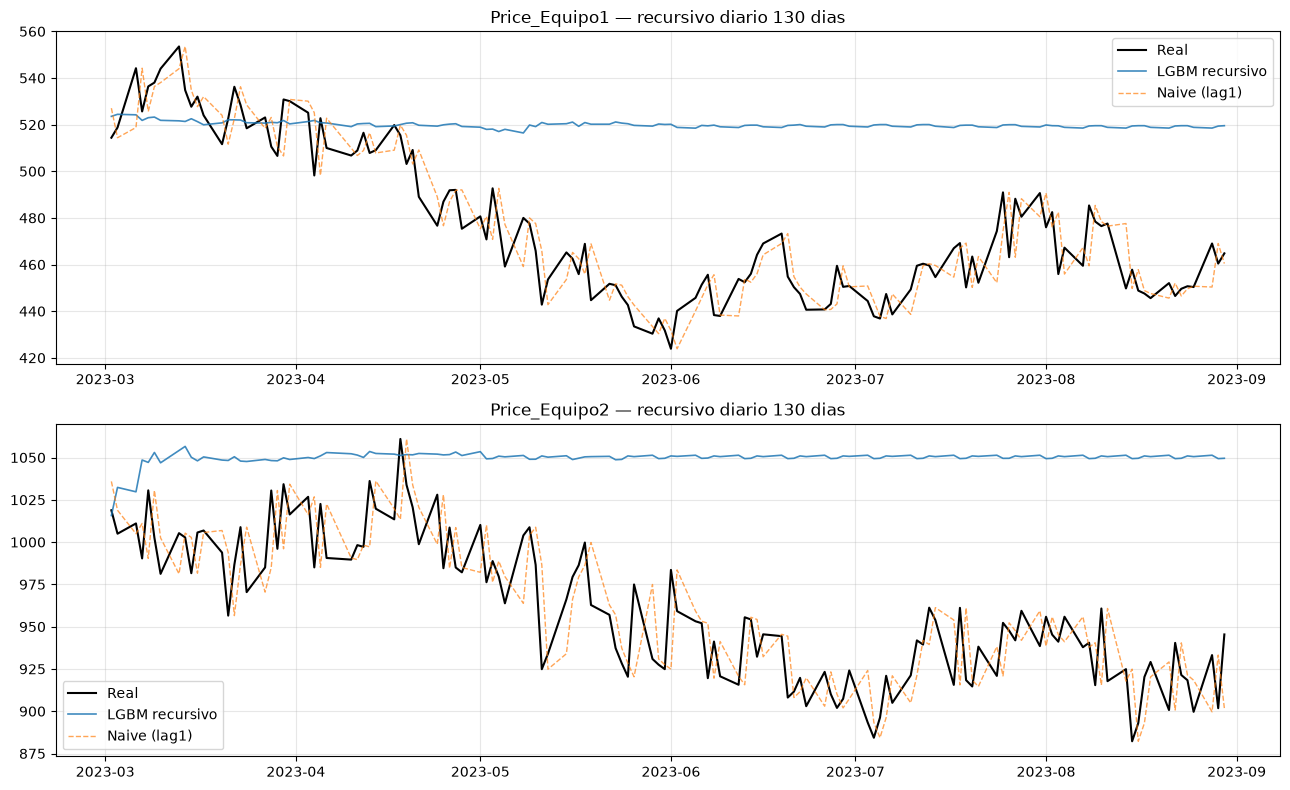

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for ax, target in zip(axes, TARGETS):
    df_res = daily_results[target]
    ax.plot(df_res.index, df_res["real"], label="Real", lw=1.5, color="black")
    ax.plot(df_res.index, df_res["lgbm"], label="LGBM recursivo", lw=1.2, alpha=0.85)
    ax.plot(df_res.index, df_res["naive"], label="Naive (lag1)", lw=1, ls="--", alpha=0.7)
    ax.set_title(f"{target} — recursivo diario {TEST_DAYS} dias")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
savefig("04_diario_recursivo")
plt.show()

El modelo recursivo deriva, asumir que el precio de hoy es el de mañana es una de las mejores estrategias y baseline dificil de vencer

In [10]:
rows = []
for target, df_res in daily_results.items():
    for h0, h1 in [(0, 20), (20, 60), (60, 100), (100, TEST_DAYS)]:
        seg = df_res.iloc[h0:h1]
        rows.append({
            "target": target, "ventana": f"d+{h0+1}..d+{h1}",
            "MAE_LGBM": mean_absolute_error(seg["real"], seg["lgbm"]),
            "MAE_naive": mean_absolute_error(seg["real"], seg["naive"]),
        })
df_hor = pd.DataFrame(rows)
df_hor["ratio_LGBM/naive"] = (df_hor["MAE_LGBM"] / df_hor["MAE_naive"]).round(3)
display(df_hor.set_index(["target", "ventana"]))

MAE_LGBM  MAE_naive  ratio_LGBM/naive
target        ventana                                            
Price_Equipo1 d+1..d+20       10.701     10.153             1.054
              d+21..d+60      35.801     10.717             3.341
              d+61..d+100     70.310      7.198             9.768
              d+101..d+130    54.031     11.022             4.902
Price_Equipo2 d+1..d+20       47.863     22.791             2.100
              d+21..d+60      60.166     21.641             2.780
              d+61..d+100    121.076     19.297             6.274
              d+101..d+130   120.004     21.236             5.651

## Propuesta
Investigando el estandar en este tipos de problemas se encontro que una soulcion empleada es utilizar una modelo esemble, en donde la predccion sea: 
> pred = w * naive + (1-w) * LGBM
Por lo que se probaron diferentes w

In [11]:
rows = []
for target, df_res in daily_results.items():
    for w in [0.0, 0.3, 0.5, 0.7, 0.9, 1.0]:
        blend = w * df_res["naive"] + (1 - w) * df_res["lgbm"]
        rows.append({"target": target, "w_naive": w,
                     **get_metrics(df_res["real"], blend).to_dict()})
display(pd.DataFrame(rows).set_index(["target", "w_naive"]).round(3))

MAE   RMSE  MAPE (%)
target        w_naive                        
Price_Equipo1 0.000   46.708 53.748    10.202
              0.300   33.260 38.260     7.259
              0.500   24.469 28.291     5.329
              0.700   16.360 19.137     3.537
              0.900   10.316 12.701     2.184
              1.000    9.607 12.035     2.012
Price_Equipo2 0.000   90.597 99.449     9.639
              0.300   63.852 71.095     6.800
              0.500   46.847 53.035     4.987
              0.700   31.399 36.831     3.331
              0.900   21.932 26.190     2.297
              1.000   21.002 25.401     2.185

## 7. Veredicto — modelo ganador y estructura del proyecto demo

**Modelo ganador adoptado (estructura del proyecto demo):**

> **LGBM diario one-step** (features: lags 1..365 + rollings 5/20/60/90 + calendario)
> **+ ensamble ponderado con el lag-1 naive** (peso w por target: Eq1 0.7, Eq2 0.9 —
> la experimentación de arriba muestra que el naive arrastra el nivel y el modelo
> solo aporta la corrección: sin w alto, la recursión deriva)
> **+ proyección recursiva 130 días** (≈6 meses) como producto final.

La implementación productiva vive en `src/models/core.py` (config FINAL) y el
contrato de salida es `data/predictions/proyeccion_6m.json` (lo consumen el
agente IA y la API).

**Por qué no la semanal directa inicial:** además del veredicto empírico de
arriba, la proyección de 6 meses = 26 semanas directas requeriría exógenas
proyectadas 26 semanas adelante. El recursivo diario con
ensamble es más robusto, escalonable (one-step reentrenable) y calibrado.